# 01 — Planejamento do fatorial 2³ aplicado à Entrega 2

## Pergunta e limites do estudo

Este material adapta o planejamento de um experimento fatorial ao conjunto observacional de impacto da IA em estudantes. A resposta é **ΔGPA = GPA pós-semestre − GPA pré-semestre**; a população analisada é o recorte STEM + Junior. A pergunta descritiva é como o ΔGPA varia entre combinações de modo de uso da IA, ansiedade e horas tradicionais de estudo.

> **Limite de interpretação:** os dados não resultam de alocação aleatória dos alunos a tratamentos. As oito combinações são células de comparação construídas a partir de variáveis observadas; os contrastes não demonstram causalidade.

## Fatores e codificação

| Fator | −1 | +1 |
|---|---|---|
| A — uso primário da IA | Ativo: demais casos de uso | Passivo: Copywriting/Drafting ou Direct Answer Generation |
| B — ansiedade em provas | ≤ mediana (Q2) | > mediana (Q2) |
| C — horas tradicionais de estudo | ≤ mediana (Q2) | > mediana (Q2) |

O corte pela mediana usa todos os alunos STEM + Junior antes da análise. Como ansiedade é discreta, os grupos podem não conter exatamente metade da amostra.

## Unidade, resposta e replicação

- **Unidade observacional:** aluno; cada ID deve aparecer uma vez.
- **Resposta:** diferença individual entre GPA pós e pré.
- **Tamanho do recorte:** não se força um n igual por célula; as células observadas são desbalanceadas.
- **Bootstrap:** reamostra alunos dentro de cada célula para estimar incerteza dos efeitos; não cria novas unidades experimentais.

O código abaixo enumera os oito vértices na ordem de Yates e mostra os tamanhos e médias observados. A ordem de Yates é uma organização dos contrastes, não a ordem de execução de um experimento aleatorizado.

In [4]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

from visualizacoes import (
    configure_plots, plot_cell_counts, plot_factorial_cube,
    plot_protocol_flow, plot_quality_dashboard, save_figure,
)
from scipy import stats
from IPython.display import display

configure_plots()

DATA_NAME = "ai_student_impact_dataset.csv"
ROOT = next(
    (base for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "csv" / DATA_NAME).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        f"Não encontrei csv/{DATA_NAME} em nenhum diretório ancestral "
        f"do diretório atual: {Path.cwd()}"
    )
CSV_PATH = ROOT / "csv" / DATA_NAME
df = pd.read_csv(CSV_PATH)

required = {
    "Student_ID", "Major_Category", "Year_of_Study", "Pre_Semester_GPA",
    "Post_Semester_GPA", "Primary_Use_Case", "Anxiety_Level_During_Exams",
    "Traditional_Study_Hours",
}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes no CSV: {sorted(missing_columns)}")

df["Delta_GPA"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
PASSIVE_USE_CASES = {"Copywriting/Drafting", "Direct_Answer_Generation"}
df["A"] = np.where(df["Primary_Use_Case"].isin(PASSIVE_USE_CASES), 1, -1)
stem_junior = df.loc[
    (df["Major_Category"] == "STEM") & (df["Year_of_Study"] == "Junior")
].copy()

ANXIETY_Q2 = stem_junior["Anxiety_Level_During_Exams"].median()
STUDY_Q2 = stem_junior["Traditional_Study_Hours"].median()
stem_junior["B"] = np.where(
    stem_junior["Anxiety_Level_During_Exams"] > ANXIETY_Q2, 1, -1
)
stem_junior["C"] = np.where(
    stem_junior["Traditional_Study_Hours"] > STUDY_Q2, 1, -1
)
factorial = stem_junior.copy()

YATES = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
CELLS = [
    (a, b, c)
    for c in (-1, 1)
    for b in (-1, 1)
    for a in (-1, 1)
]
cell_number = {cell: number for number, cell in enumerate(CELLS, start=1)}
factorial["celula"] = [
    cell_number[(int(row.A), int(row.B), int(row.C))]
    for row in factorial[["A", "B", "C"]].itertuples(index=False)
]
groups = {
    key: frame["Delta_GPA"].to_numpy()
    for key, frame in factorial.groupby(["A", "B", "C"], sort=False)
}
cell_counts = factorial.groupby(["A", "B", "C"]).size()
if set(groups) != set(CELLS):
    raise ValueError("A classificação não produziu as oito células fatoriais.")
if factorial["Delta_GPA"].isna().any():
    raise ValueError("Há ΔGPA ausente; resolva os dados ausentes antes da análise.")

print(f"Arquivo: {CSV_PATH}")
print(f"Dataset completo: n={len(df):,}")
print(f"Recorte STEM + Junior: n={len(stem_junior):,}")
print(f"Analisados nas oito células: n={len(factorial):,}")
print(f"Cortes: ansiedade Q2={ANXIETY_Q2:g}; estudo Q2={STUDY_Q2:.2f} h")
print(f"Menor célula: n={cell_counts.min():,}")

configure_plots()


Arquivo: /home/wagner/pcc170/csv/ai_student_impact_dataset.csv
Dataset completo: n=50,000
Recorte STEM + Junior: n=3,279
Analisados nas oito células: n=3,279
Cortes: ansiedade Q2=4; estudo Q2=10.91 h
Menor célula: n=181


## Tabela do desenho observado

A tabela é descritiva: cada linha contém alunos que compartilham os mesmos níveis codificados.

In [5]:

YATES = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
design_rows = []
for label, (a, b, c) in zip(YATES, CELLS):
    sample = factorial.loc[
        (factorial["A"] == a) & (factorial["B"] == b) & (factorial["C"] == c),
        "Delta_GPA",
    ]
    design_rows.append({
        "Ensaio Yates": label,
        "A (IA)": "Passivo" if a == 1 else "Ativo",
        "B (ansiedade)": "Alta" if b == 1 else "Baixa",
        "C (estudo)": "Alto" if c == 1 else "Baixo",
        "n": len(sample),
        "média ΔGPA": sample.mean(),
        "DP ΔGPA": sample.std(ddof=1),
    })
design = pd.DataFrame(design_rows)
display(design.round(3))


,Ensaio Yates,A (IA),B (ansiedade),C (estudo),n,média ΔGPA,DP ΔGPA
0,(1),Ativo,Baixa,Baixo,667,0.196,0.172
1,a,Passivo,Baixa,Baixo,210,0.152,0.198
2,b,Ativo,Alta,Baixo,576,0.201,0.184
3,ab,Passivo,Alta,Baixo,187,0.091,0.236
4,c,Ativo,Baixa,Alto,639,0.317,0.170
5,ac,Passivo,Baixa,Alto,235,0.252,0.176
6,bc,Ativo,Alta,Alto,584,0.323,0.173
7,abc,Passivo,Alta,Alto,181,0.233,0.179


## Desenho visual e balanceamento observado

O cubo mostra a média de ΔGPA em cada combinação; a figura de contagens explicita que este desenho observacional não tem replicação balanceada.

Figura salva: 01_cubo_fatorial_resposta.png (PNG) e 01_cubo_fatorial_resposta.pdf (PDF)


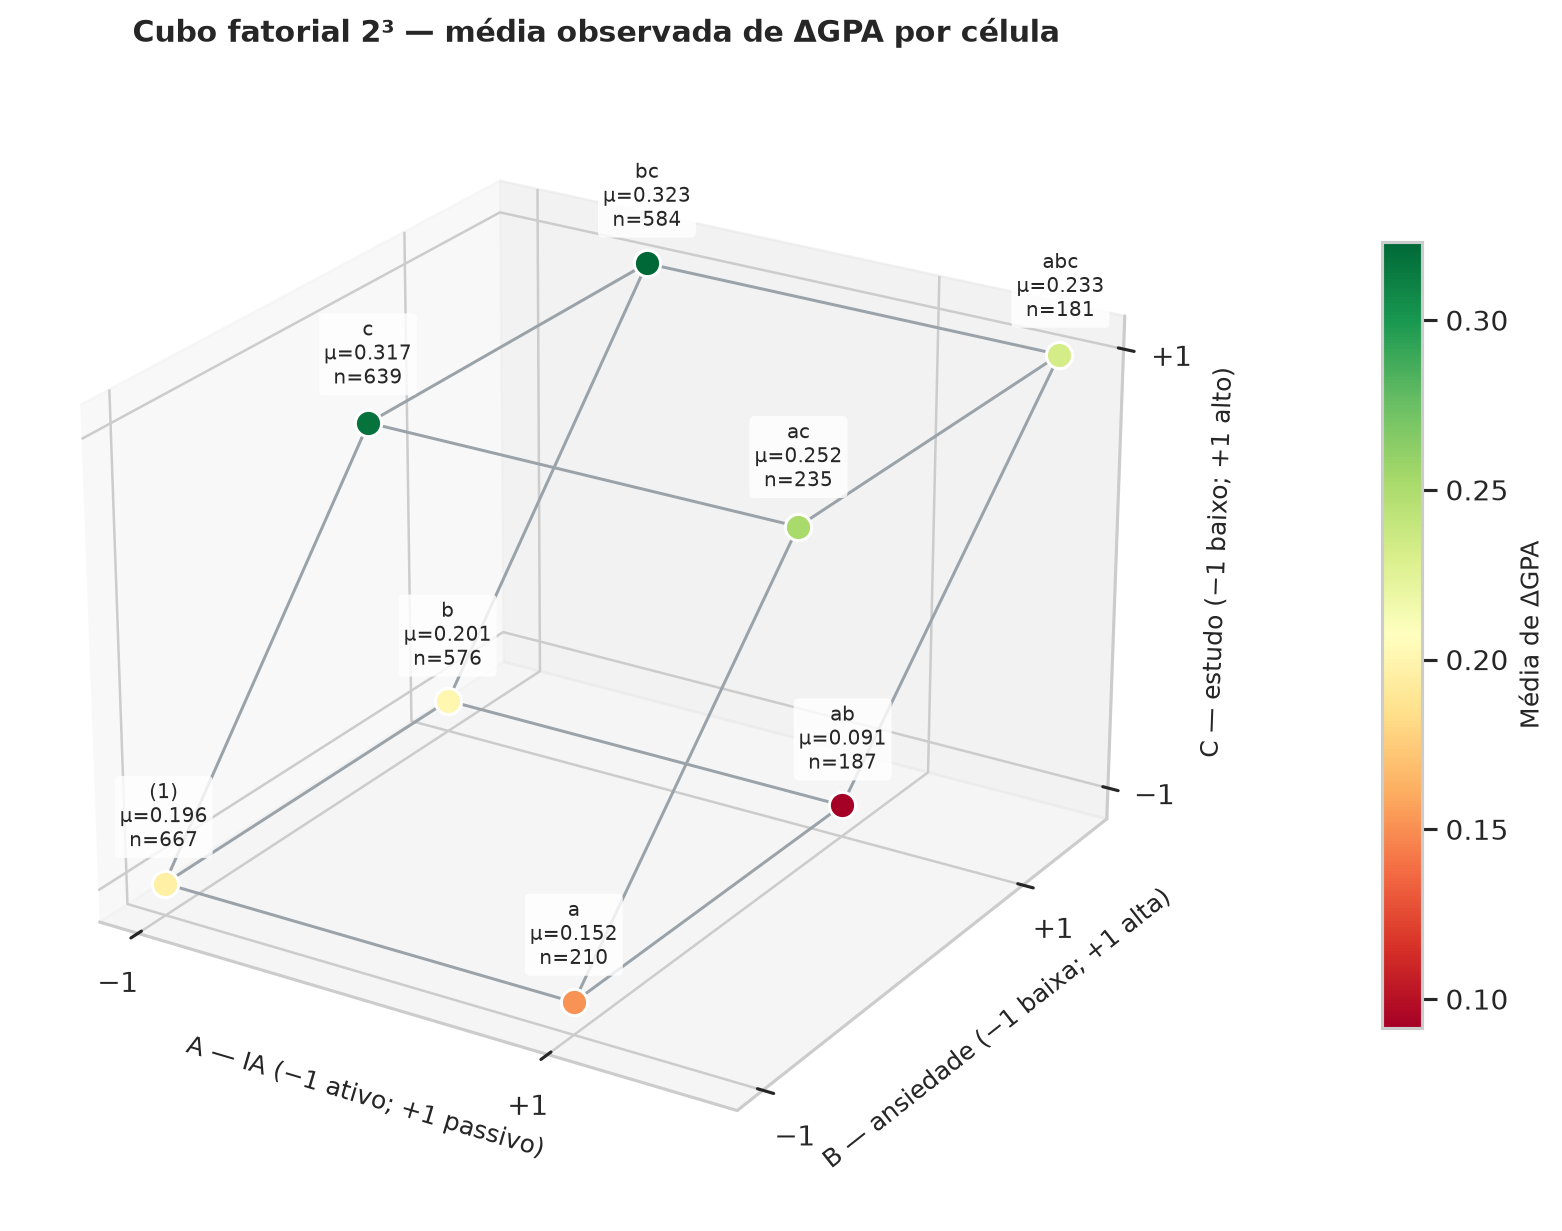

Figura salva: 01_tamanho_celulas.png (PNG) e 01_tamanho_celulas.pdf (PDF)


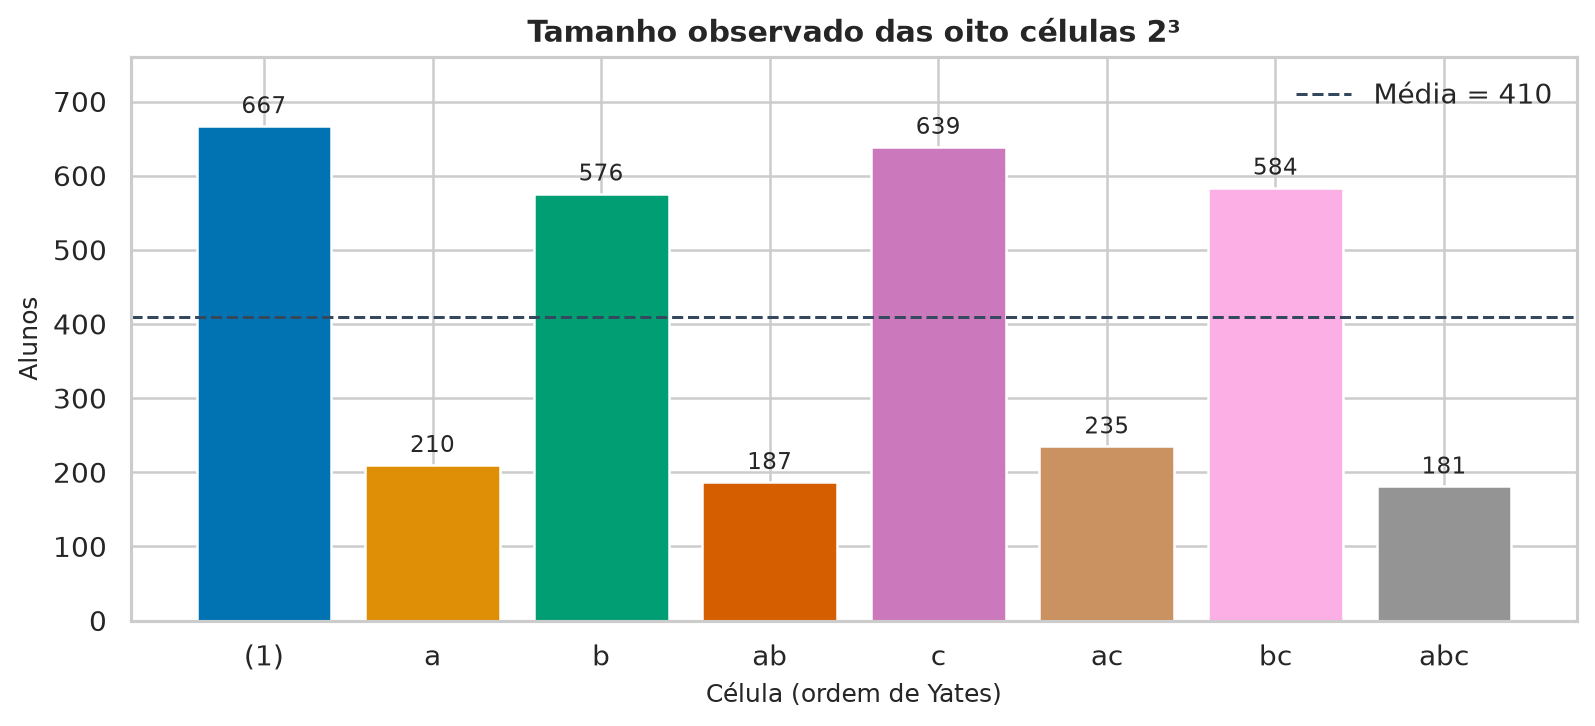

In [6]:
cell_means = {cell: groups[cell].mean() for cell in CELLS}
cell_counts = {cell: len(groups[cell]) for cell in CELLS}
fig = plot_factorial_cube(cell_means, cell_counts)
save_figure(fig, "01_cubo_fatorial_resposta")

fig = plot_cell_counts(
    [cell_counts[cell] for cell in CELLS],
    YATES,
    title="Tamanho observado das oito células 2³",
)
save_figure(fig, "01_tamanho_celulas")


## Hipóteses de trabalho

- **A:** uso passivo da IA está associado a menor ΔGPA do que uso ativo.
- **B:** ansiedade alta está associada a menor ΔGPA.
- **C:** estudo acima da mediana está associado a maior ΔGPA.
- **AB, AC, BC, ABC:** verificam se as associações dependem da combinação dos fatores.

As hipóteses descrevem contrastes, não efeitos causais. O plano principal mantém os fatores binários para comparar diretamente com o desenho 2³ dos materiais da disciplina; a regressão contínua e os cortes por quartis ficam como análises de sensibilidade.